
# 04 – Model Evaluation and Error Analysis

## 1. Introduction

This notebook evaluates the performance of the trained Random Forest Regression models developed for electricity demand forecasting in Tetuan City.

The evaluation focuses on all three electricity consumption zones.

## 2. Objectives

- Evaluate the trained Random Forest models.
- Measure prediction performance using MAE, RMSE and R².
- Compare actual and predicted electricity consumption.
- Visualize forecasting performance.
- Analyze prediction errors for each zone.
- Identify areas for model improvement.

## 3. Evaluation Methodology

The trained models will be evaluated using the unseen test dataset to assess their ability to predict electricity demand one hour ahead.


In [1]:

# 1. IMPORT REQUIRED LIBRARIES

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully!")


Libraries imported successfully!


## 2. Evaluation Methodology

The trained Random Forest models will be evaluated using the unseen test dataset.

The following performance metrics will be used:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R-squared (R²)

The evaluation will be performed separately for Zone 1, Zone 2 and Zone 3.

## 3. Loading Trained Models

In this section, the previously trained Random Forest models for Zone 1, Zone 2 and Zone 3 are loaded from the models folder.

In [2]:

from pathlib import Path
import os

print("CURRENT NOTEBOOK LOCATION:")
print(Path.cwd())

print("\nALL JOBLIB FILES FOUND:")

project_folder = Path.cwd().parent

for file in project_folder.rglob("*.joblib"):
    print(file)
    
print("\nMODEL FILE CHECK:")

for name in [
    "Zone_1_Target_rf.joblib",
    "Zone_2_Target_rf.joblib",
    "Zone_3_Target_rf.joblib"
]:
    matches = list(project_folder.rglob(name))
    print(name, "FOUND" if matches else "NOT FOUND")


CURRENT NOTEBOOK LOCATION:
c:\Users\gowth\Downloads\Power Consumption\notebooks

ALL JOBLIB FILES FOUND:
c:\Users\gowth\Downloads\Power Consumption\models\Zone_1_Target_rf.joblib
c:\Users\gowth\Downloads\Power Consumption\models\Zone_2__Target_rf.joblib
c:\Users\gowth\Downloads\Power Consumption\models\Zone_3__Target_rf.joblib

MODEL FILE CHECK:
Zone_1_Target_rf.joblib FOUND
Zone_2_Target_rf.joblib NOT FOUND
Zone_3_Target_rf.joblib NOT FOUND


In [3]:

# ==========================================
# 3. LOAD TRAINED RANDOM FOREST MODELS
# ==========================================

import joblib
from pathlib import Path

# Locate models folder
models_dir = Path.cwd().parent / "models"

# Actual saved filenames
model_files = {
    "Zone 1": "Zone_1_Target_rf.joblib",
    "Zone 2": "Zone_2__Target_rf.joblib",
    "Zone 3": "Zone_3__Target_rf.joblib"
}

# Load models
trained_models = {}

for zone, filename in model_files.items():

    model_path = models_dir / filename

    if not model_path.exists():
        raise FileNotFoundError(f"Missing model: {model_path}")

    trained_models[zone] = joblib.load(model_path)

    print(f"{zone} model loaded successfully!")

print("\nALL TRAINED MODELS LOADED SUCCESSFULLY!")
print("Total models loaded:", len(trained_models))


Zone 1 model loaded successfully!
Zone 2 model loaded successfully!
Zone 3 model loaded successfully!

ALL TRAINED MODELS LOADED SUCCESSFULLY!
Total models loaded: 3


## 4. Model Performance Evaluation

The trained Random Forest models will now be evaluated using the unseen test dataset.

The performance of each model will be measured using MAE, RMSE, and R-squared (R²) metrics for Zone 1, Zone 2, and Zone 3.

In [11]:

from pathlib import Path
import re
import joblib
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Find the project folder automatically
cwd = Path.cwd()

possible_roots = [cwd, cwd.parent]
project_root = next(
    (p for p in possible_roots
     if (p / "models").is_dir()
     and (p / "outputs" / "engineered_power_data.csv").exists()),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Cannot find the project folder containing models/ and outputs/."
    )

models_dir = project_root / "models"
outputs_dir = project_root / "outputs"

# 2. Load the engineered dataset
df = pd.read_csv(outputs_dir / "engineered_power_data.csv")
df["DateTime"] = pd.to_datetime(df["DateTime"])

target_cols = [c for c in df.columns if c.endswith("_Target")]
feature_cols = [
    c for c in df.columns
    if c not in target_cols and c != "DateTime"
]

# 3. Re-create the same chronological split
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

test_df = df.iloc[val_end:].copy()

# 4. Find each model by its Zone number.
# This handles filenames with either one or two underscores.
model_paths = list(models_dir.glob("*_rf.joblib"))

def normalize_name(value):
    return re.sub(r"[^a-z0-9]", "", value.lower())

trained_models = {}

for zone_number in [1, 2, 3]:
    expected = f"zone{zone_number}targetrf"

    matches = [
        path for path in model_paths
        if normalize_name(path.stem) == expected
    ]

    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected one model for Zone {zone_number}, "
            f"but found: {[p.name for p in matches]}. "
            f"Available files: {[p.name for p in model_paths]}"
        )

    trained_models[f"Zone {zone_number}"] = joblib.load(matches[0])
    print(f"Loaded: {matches[0].name}")

# 5. Evaluate all three models on the test data
results = []

for zone_number in [1, 2, 3]:
    zone = f"Zone {zone_number}"
    model = trained_models[zone]

    # Match the exact target column
    target_matches = [
        c for c in target_cols
        if normalize_name(c) == f"zone{zone_number}target"
    ]

    if len(target_matches) != 1:
        raise ValueError(
            f"Could not uniquely identify the target for {zone}: "
            f"{target_matches}"
        )

    target = target_matches[0]

    # Preserve the feature names and order used during training
    if hasattr(model, "feature_names_in_"):
        model_features = list(model.feature_names_in_)
        missing = [c for c in model_features if c not in test_df.columns]

        if missing:
            raise ValueError(f"Missing model features: {missing}")

        X_test = test_df[model_features]
    else:
        X_test = test_df[feature_cols]

    y_test = test_df[target]
    y_pred = model.predict(X_test)

    results.append({
        "Zone": zone,
        "Target": target,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred),
        "Test_Records": len(y_test)
    })

evaluation_df = pd.DataFrame(results)

# 6. Save and display the evaluation results
evaluation_df.to_csv(
    outputs_dir / "model_evaluation_results.csv",
    index=False
)

print("\nFINAL TEST EVALUATION")
display(evaluation_df.round(4))

print("\nSaved: outputs/model_evaluation_results.csv")


Loaded: Zone_1_Target_rf.joblib
Loaded: Zone_2__Target_rf.joblib
Loaded: Zone_3__Target_rf.joblib

FINAL TEST EVALUATION


,Zone,Target,MAE,RMSE,R2,Test_Records
0,Zone 1,Zone 1_Target,1802.5843,2155.4920,0.8737,7840
1,Zone 2,Zone 2 _Target,993.9049,1608.8562,0.9173,7840
2,Zone 3,Zone 3 _Target,2086.2567,2491.7866,0.4509,7840



Saved: outputs/model_evaluation_results.csv


## 5. Error Analysis

This section analyzes the prediction errors of the trained Random Forest models for Zone 1, Zone 2 and Zone 3.

Actual and predicted electricity consumption values will be compared to understand model accuracy and identify prediction errors.

The analysis will include:
- Actual vs Predicted values
- Prediction error calculation
- Error distribution visualization

In [5]:
# ==========================================
# 5. ERROR ANALYSIS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Normalize column names to handle spaces and underscores
def normalize_name(name):
    return "".join(ch.lower() for ch in name if ch.isalnum())


# Find actual target columns
target_lookup = {
    normalize_name(col): col
    for col in test_df.columns
}

# Store error analysis results
error_results = {}

# Analyze each zone
for zone, model in trained_models.items():

    target_key = normalize_name(zone + "_Target")

    if target_key not in target_lookup:
        raise KeyError(
            f"Target column not found for {zone}. "
            f"Available columns: {list(test_df.columns)}"
        )

    target = target_lookup[target_key]

    # Prepare test data
    X_test = test_df[feature_cols]
    y_test = test_df[target]

    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate errors
    errors = y_test.values - y_pred

    # Store results
    error_results[zone] = {
        "Actual": y_test.values,
        "Predicted": y_pred,
        "Error": errors
    }

    print(f"\n{zone} Error Analysis")
    print("--------------------------------")

    print("Mean Error:", round(np.mean(errors), 2))
    print("Mean Absolute Error:",
          round(np.mean(np.abs(errors)), 2))
    print("Maximum Absolute Error:",
          round(np.max(np.abs(errors)), 2))
    print("Minimum Absolute Error:",
          round(np.min(np.abs(errors)), 2))

print("\nALL ZONE ERROR ANALYSIS COMPLETED!")


Zone 1 Error Analysis
--------------------------------
Mean Error: -1425.83
Mean Absolute Error: 1949.52
Maximum Absolute Error: 7266.46
Minimum Absolute Error: 0.68

Zone 2 Error Analysis
--------------------------------
Mean Error: 359.65
Mean Absolute Error: 1084.41
Maximum Absolute Error: 10126.77
Minimum Absolute Error: 0.01

Zone 3 Error Analysis
--------------------------------
Mean Error: -1668.38
Mean Absolute Error: 2170.2
Maximum Absolute Error: 6765.49
Minimum Absolute Error: 0.15

ALL ZONE ERROR ANALYSIS COMPLETED!


## 6. Actual vs Predicted Visualization

This section compares actual electricity consumption with predicted consumption for each zone.

The visualizations help identify how closely the Random Forest models follow actual electricity demand patterns.

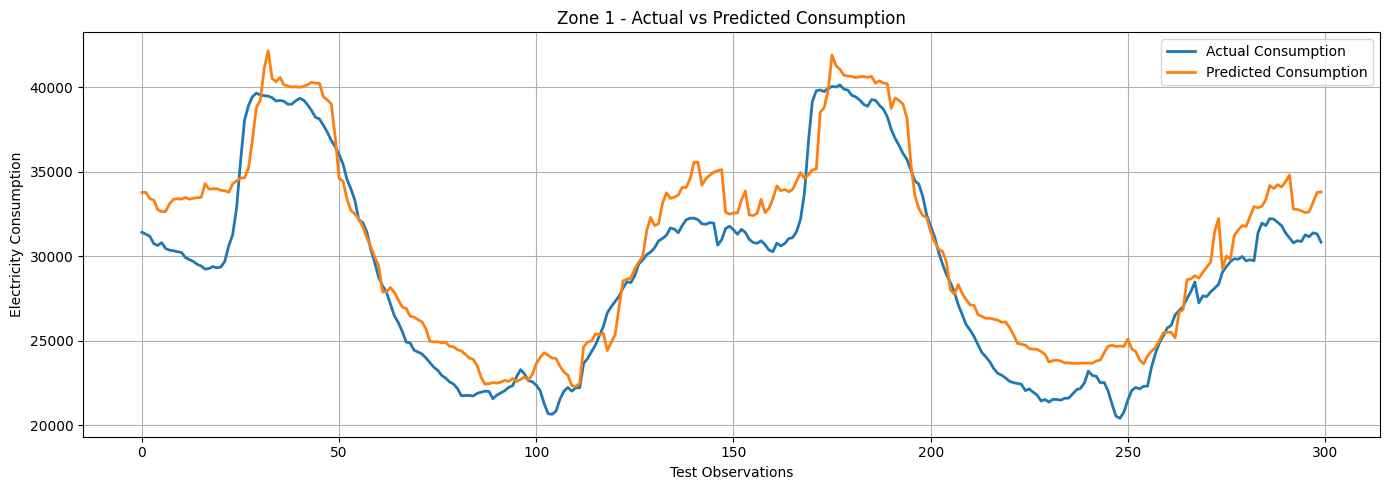

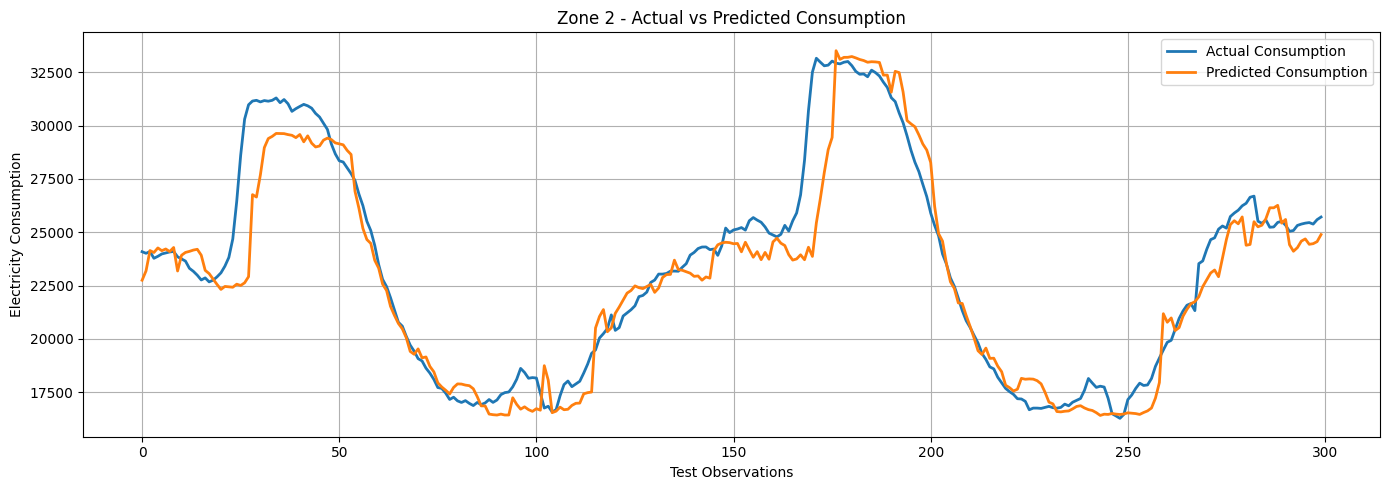

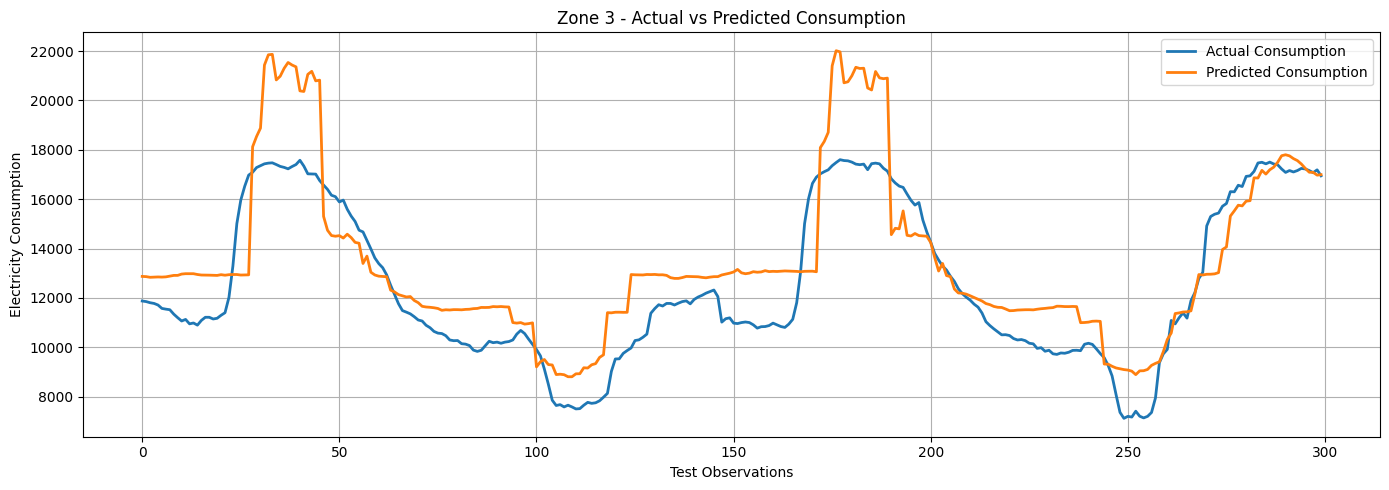

ALL VISUALIZATIONS COMPLETED!


In [6]:
# Actual vs Predicted Visualization

for zone, results in error_results.items():

    plt.figure(figsize=(14, 5))

    # Display a sample of 300 test observations
    sample_size = min(300, len(results["Actual"]))

    plt.plot(
        results["Actual"][:sample_size],
        label="Actual Consumption",
        linewidth=2
    )

    plt.plot(
        results["Predicted"][:sample_size],
        label="Predicted Consumption",
        linewidth=2
    )

    plt.title(f"{zone} - Actual vs Predicted Consumption")
    plt.xlabel("Test Observations")
    plt.ylabel("Electricity Consumption")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

print("ALL VISUALIZATIONS COMPLETED!")

## 7. Prediction Error Distribution

This section examines the distribution of prediction errors for each zone.

Error distribution plots help identify whether prediction errors are concentrated around zero or show systematic deviations.

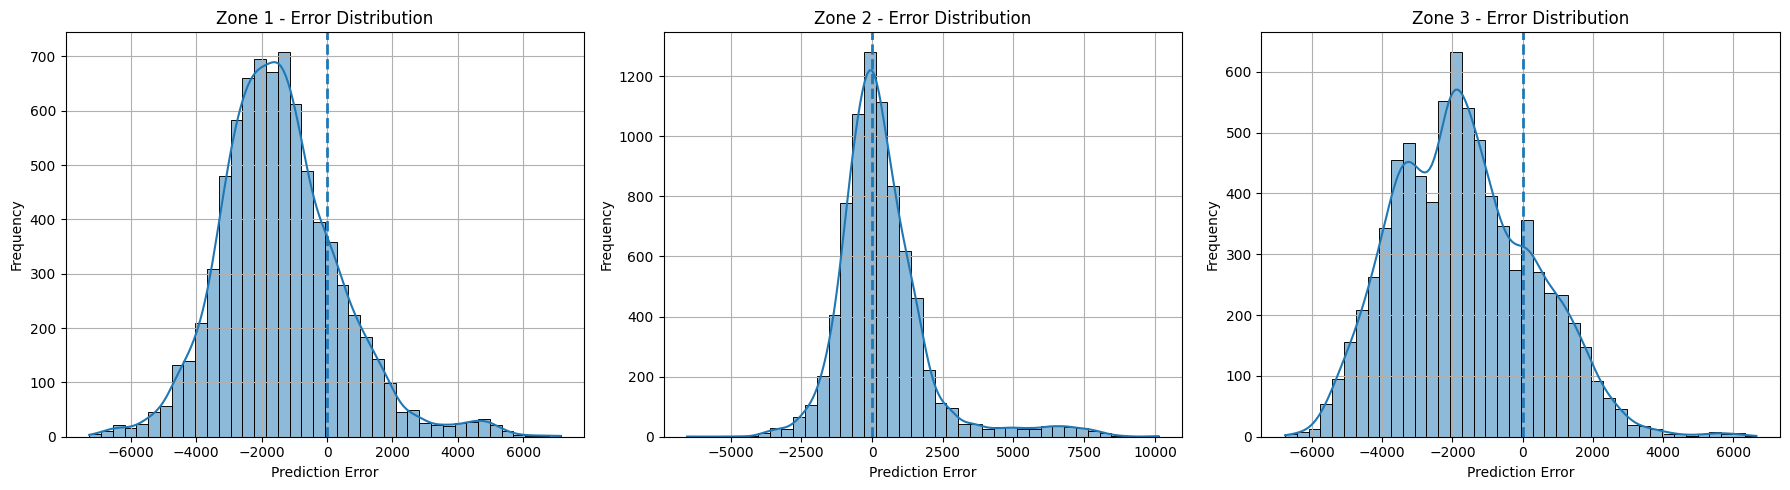

ERROR DISTRIBUTION VISUALIZATION COMPLETED!


In [7]:
# Prediction Error Distribution

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (zone, results) in zip(axes, error_results.items()):

    sns.histplot(
        results["Error"],
        bins=40,
        kde=True,
        ax=ax
    )

    ax.axvline(0, linestyle="--", linewidth=2)
    ax.set_title(f"{zone} - Error Distribution")
    ax.set_xlabel("Prediction Error")
    ax.set_ylabel("Frequency")
    ax.grid(True)

plt.tight_layout()
plt.show()

print("ERROR DISTRIBUTION VISUALIZATION COMPLETED!")

## 8. Residual Analysis

Residual analysis examines the relationship between predicted electricity consumption and prediction errors for each zone.

This helps identify systematic prediction patterns and potential model weaknesses.

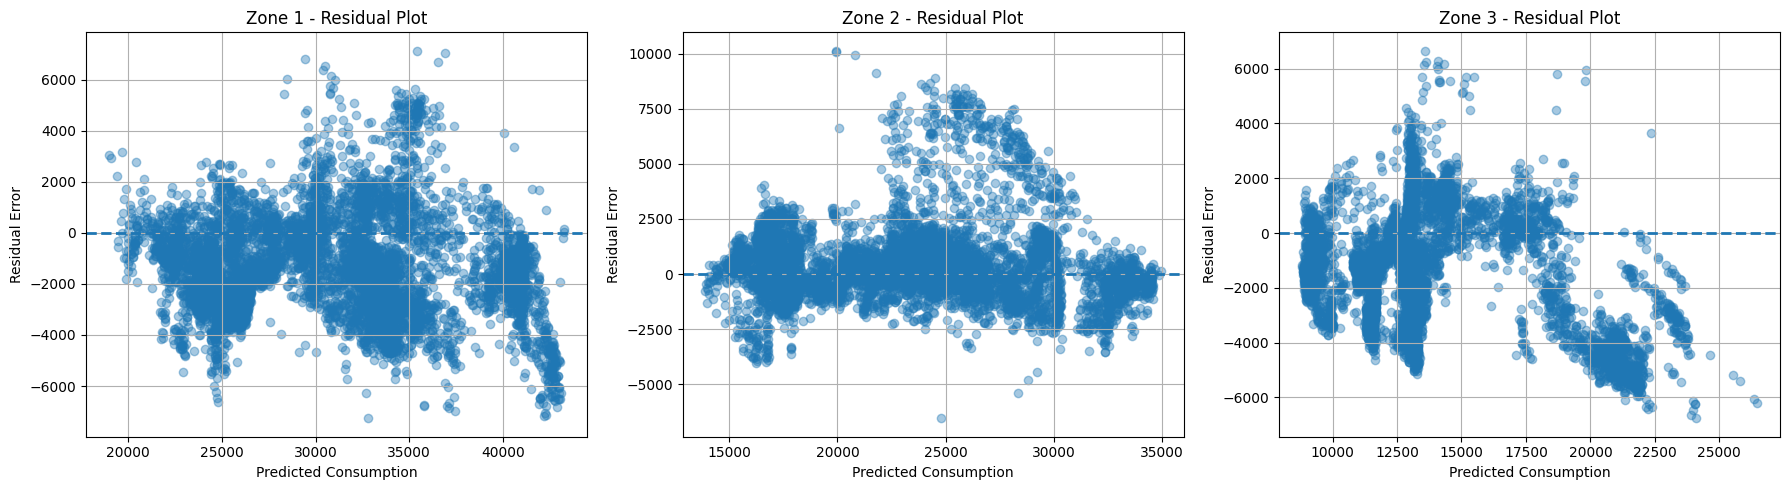

RESIDUAL ANALYSIS COMPLETED!


In [8]:
# Residual Analysis

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (zone, results) in zip(axes, error_results.items()):

    ax.scatter(
        results["Predicted"],
        results["Error"],
        alpha=0.4
    )

    ax.axhline(0, linestyle="--", linewidth=2)

    ax.set_title(f"{zone} - Residual Plot")
    ax.set_xlabel("Predicted Consumption")
    ax.set_ylabel("Residual Error")
    ax.grid(True)

plt.tight_layout()
plt.show()

print("RESIDUAL ANALYSIS COMPLETED!")

## 9. Final Model Evaluation Summary

This section summarizes the performance of all three Random Forest models using MAE, RMSE and R-squared scores.

The results are compared to identify the best-performing model and the zone requiring further improvement.

In [9]:
# Final Model Evaluation Summary

summary_df = evaluation_df.copy()

summary_df["Performance"] = summary_df["R2 Score"].apply(
    lambda x: "Good" if x >= 0.80
    else "Moderate" if x >= 0.60
    else "Needs Improvement"
)

display(summary_df)

# Identify best and weakest models
best_zone = summary_df.loc[
    summary_df["R2 Score"].idxmax(), "Zone"
]

weakest_zone = summary_df.loc[
    summary_df["R2 Score"].idxmin(), "Zone"
]

print("BEST PERFORMING MODEL:", best_zone)
print("MODEL NEEDING IMPROVEMENT:", weakest_zone)

,Zone,Target Column,MAE,RMSE,R2 Score,Performance
0,Zone 1,Zone 1_Target,1949.519533,2338.556558,0.851370,Good
1,Zone 2,Zone 2 _Target,1084.412639,1685.524804,0.909269,Good
2,Zone 3,Zone 3 _Target,2170.200838,2576.249491,0.413045,Needs Improvement


BEST PERFORMING MODEL: Zone 2
MODEL NEEDING IMPROVEMENT: Zone 3
